# 공모펀드마스터(PRFD01N001) EDA

**데이터셋**: `PRFD01N001_공모펀드마스터`
**최종 추출일자(스키마 기준)**: 2026-07-11
**목적**: 공모펀드 마스터 데이터의 구조, 결측/이상치, 범주형·수치형 분포, 수익률·순자산·투자위험등급 특성을 탐색


**PK 관련 주의**: 스키마 파일에는 `itm_no`, `prfd_attr_cd`, `zrin_fd_ivst_risk_gcd` 세 컬럼이 모두 `PK`로 표기되어 있습니다. 의미상 `itm_no`(종목번호)가 실제 기본키일 가능성이 높고, 나머지 둘은 분류 코드로 보이므로 6번 섹션에서 셋을 각각 개별 점검합니다. 실제 raw 데이터를 보고 진짜 PK를 확정해주세요.

**스키마 vs 샘플시트 불일치**: 제공된 스키마 파일의 `Sheet2_Sample`은 `Sheet1_Schema`의 45개 컬럼과 다른 컬럼 구성(`itm_no`, `itm_nm`, `itm_abrv_nm`, `fd_nast_suma`, `or_attr_desc` + `axis_fundType`, `axis_redemptionType`, `axis_issuanceType`, `axis_listingType`, `axis_classDifferentiation`, `axis_investorEligibility`)을 가지고 있습니다. `axis_*` 컬럼은 온톨로지 설계에서 쓸 상위 분류 축으로 보이며, 이 노트북의 21번 섹션에서 별도로 정리합니다.

## 1. 라이브러리 임포트 및 환경 설정

In [6]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

%matplotlib inline


In [7]:
# --- 차트 스타일 (색상 시스템: 고정 순서 카테고리 팔레트) -------------------
# 국내채권마스터 EDA 노트북과 동일한 팔레트를 재사용해 두 노트북 간 시각적 일관성을 유지합니다.
# 카테고리형 변수를 그릴 때는 항상 이 순서(CAT_COLORS)를 그대로 사용하고,
# 그룹이 8개를 넘으면 상위 N개 + "기타"로 묶어서 사용합니다.
CAT_COLORS = [
    "#2a78d6",  # 1 blue
    "#eb6834",  # 2 orange
    "#1baf7a",  # 3 aqua
    "#eda100",  # 4 yellow
    "#e87ba4",  # 5 magenta
    "#008300",  # 6 green
    "#4a3aa7",  # 7 violet
    "#e34948",  # 8 red
]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_BLUE_CMAP = sns.blend_palette(SEQ_BLUE, as_cmap=True)
DIVERGING_CMAP = sns.diverging_palette(220, 10, s=75, l=50, sep=10, as_cmap=True)  # blue-gray-red

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRIDLINE,
    "grid.linewidth": 0.6,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.dpi": 110,
})


def cat_colors(n: int) -> list:
    '''카테고리 개수만큼 고정 순서 팔레트에서 색을 가져온다. 8개 초과 시 순환하지 않고 반복 사용을 피하려면
    호출 전에 top-N + "기타"로 묶는 것을 권장.'''
    if n <= len(CAT_COLORS):
        return CAT_COLORS[:n]
    reps = (n // len(CAT_COLORS)) + 1
    return (CAT_COLORS * reps)[:n]


## 2. 데이터 로드

`DATA_PATH`만 실제 파일 경로로 바꿔서 사용하세요. csv / parquet / xlsx 로더를 모두 준비해뒀고,
`DATA_PATH`의 확장자에 따라 자동으로 분기합니다.

In [8]:
# TODO: 실제 데이터 경로로 수정

DATA_PATH = Path("../perprocessed_datas/v4/PRFD01N001_공모펀드마스터_20260711_datarows.xlsx")

# 스키마 기준 컬럼 순서 (raw 데이터 컬럼명이 다르면 여기만 맞춰서 조정)
SCHEMA_COLUMNS = [
    "itm_no", "itm_nm", "itm_abrv_nm", "itm_eng_nm", "itm_eabrv_nm",
    "fss_itm_no", "ksd_itm_no", "mtco_itm_no", "rptt_ksd_itm_no", "std_itm_no",
    "kofia_fd_ccd", "prfd_attr_cd", "or_co_xtn_itt_cd", "trusc_xtn_itt_cd",
    "bmrk_nm", "bmrk_eng_nm",
    "fd_estb_ctry_cd", "fd_ivst_rgn_desc", "fd_set_pcd", "or_attr_desc",
    "ovrs_fd_desc", "pers_corp_desc", "prvo_fd_desc", "prvo_pbff_desc",
    "int_dvd_desc", "zrin_fd_ivst_risk_gcd", "zrin_fd_ivst_risk_grd_nm",
    "curr_cd", "sale_yn", "pfiv_sale_cntl_tcd",
    "exchdg_yn", "frc_bpr_itm_yn", "hdge_fd_yn", "ofsfd_yn", "thco_sale_yn",
    "fd_wk1_ern_r", "fd_mm1_ern_r", "fd_mm3_ern_r", "fd_mm6_ern_r", "fd_mm18_ern_r",
    "fd_yr1_ern_r", "fd_yr2_ern_r", "fd_yr3_ern_r", "fd_yr5_ern_r",
    "fd_nast_suma",
]


def load_fund_master(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in (".parquet", ".pq"):
        return pd.read_parquet(path)
    if suffix in (".xlsx", ".xls"):
        return pd.read_excel(path)
    raise ValueError(f"지원하지 않는 확장자입니다: {suffix}")


df_raw = load_fund_master(DATA_PATH)
print(f"Loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} cols")
df_raw.head()


Loaded: 95,619 rows x 45 cols


,bmrk_eng_nm,bmrk_nm,curr_cd,exchdg_yn,fd_estb_ctry_cd,fd_ivst_rgn_desc,fd_mm18_ern_r,fd_mm1_ern_r,fd_mm3_ern_r,fd_mm6_ern_r,fd_nast_suma,fd_set_pcd,fd_wk1_ern_r,fd_yr1_ern_r,fd_yr2_ern_r,fd_yr3_ern_r,fd_yr5_ern_r,frc_bpr_itm_yn,fss_itm_no,hdge_fd_yn,int_dvd_desc,itm_abrv_nm,itm_eabrv_nm,itm_eng_nm,itm_nm,itm_no,kofia_fd_ccd,ksd_itm_no,mtco_itm_no,ofsfd_yn,or_attr_desc,or_co_xtn_itt_cd,ovrs_fd_desc,pers_corp_desc,pfiv_sale_cntl_tcd,prfd_attr_cd,prvo_fd_desc,prvo_pbff_desc,rptt_ksd_itm_no,sale_yn,std_itm_no,thco_sale_yn,trusc_xtn_itt_cd,zrin_fd_ivst_risk_gcd,zrin_fd_ivst_risk_grd_nm
0,채권종합 3M~1Y,종합채권 3개월~1년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,"77,291,400,582.0000",20.0000,NaN,NaN,NaN,NaN,NaN,N,0010173C9824,N,배당,삼성1.5년매칭형증권투자제1호[채권]C-P,NaN,삼성1.5년매칭형증권투자신탁제1호[채권]_C-P,삼성1.5년매칭형증권투자신탁제1호[채권]_C-P,KR5114420158,11111A327360131ZZZZ5,KRZ502532813,01MN900,N,채권형,"40,010.0000",국내,개인,0.0000,F103,해당없음,공모,0302001MN900,판매완료,K55105DY4714,Y,"20,054.0000",NaN,NaN
1,MSCI ACWI CR 75% + KIS Bond Index 01Y 25%,MSCI ACWI CR 75% + KIS채권종합01Y 25%,KRW,Y,0.0000,글로벌,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,알리안츠멀티파재F,NaN,알리안츠다이나믹멀티에셋증권투자신탁[주식혼합_파생재간접형] Class C(F),알리안츠다이나믹멀티에셋증권투자신탁[주식혼합_파생재간접형] Class C(F),KR5138490078,NaN,KRZ502024037,0060901,N,재간접,"40,023.0000",해외,해당없음,0.0000,V102,해당없음,공모,032110060901,판매완료,K55228B78547,NaN,"20,054.0000",NaN,NaN
2,KOSPI200 25% + KAP Bond Index 01Y 75%,KOSPI200 25% + 종합채권01Y 75%,KRW,NaN,0.0000,국내,47.0800,1.1800,16.2900,25.9700,"71,147,860,091.0000",10.0000,2.5500,38.1700,43.2500,60.3100,49.3700,N,0011644C0164,N,배당,한국밸류10년투자배당투자(채권혼합)AE,NaN,한국밸류10년투자 배당증권투자신탁(채권혼합)종류A-E,한국밸류10년투자 배당증권투자신탁(채권혼합)종류A-E,KR5174430032,141112120010122ZZZZ5,KRZ501944872,0010200,N,채권혼합,"80,021.0000",국내,해당없음,0.0000,M111,해당없음,공모,033910010200,판매중,KR5236AY2947,Y,"20,088.0000",4.0000,보통 위험
3,MSCI ACWI,MSCI ACWI,KRW,Y,0.0000,글로벌,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,KTB글로벌테마주식C,NaN,2014.6.30 소규모펀드 임의해지,KTB글로벌테마셀렉션증권투자신탁[주식-재간접형]_C,KR5152651012,NaN,KRZ500366082,0019004,N,재간접,"80,013.0000",해외,해당없음,0.0000,C103,해당없음,공모,032400019004,판매완료,KR5306702543,Y,"20,004.0000",NaN,NaN
4,S&P 500(KRW) 95% + CALL 5%,S&P 500(KRW) 95% + CALL 5%,KRW,N,0.0000,글로벌,28.5400,1.1600,12.7800,11.7200,"600,482,482,202.0000",10.0000,-0.8200,33.7300,48.2300,95.2400,127.9700,N,0010173C7109,N,배당,삼성미국S&P500인덱스증권자UH[주식]_Cpe(퇴직연금),NaN,삼성미국S&P500인덱스증권자투자신탁UH[주식] Cpe(퇴직),삼성미국S&P500인덱스증권자투자신탁UH[주식] Cpe(퇴직),KR5114450497,12123612060107101202,KRZ50203521G,01MA700,N,주식형,"40,010.0000",해외,해당없음,0.0000,C103,해당없음,공모,0302001MA700,판매중,K55105BU1120,Y,"20,004.0000",3.0000,다소 높은 위험


In [9]:
df = df_raw.copy()

# 컬럼명이 스키마와 대소문자만 다른 경우 등을 대비한 정규화 (필요 없으면 스킵해도 무방)
df.columns = [c.strip() for c in df.columns]

missing_from_schema = [c for c in SCHEMA_COLUMNS if c not in df.columns]
extra_in_data = [c for c in df.columns if c not in SCHEMA_COLUMNS]
print("스키마에는 있는데 데이터에 없는 컬럼:", missing_from_schema)
print("데이터에는 있는데 스키마에 없는 컬럼:", extra_in_data)


스키마에는 있는데 데이터에 없는 컬럼: []
데이터에는 있는데 스키마에 없는 컬럼: []


## 3. 기본 정보 확인

In [10]:
print(f"shape: {df.shape}")
df.info()


shape: (95619, 45)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95619 entries, 0 to 95618
Data columns (total 45 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   bmrk_eng_nm               95619 non-null  object 
 1   bmrk_nm                   95619 non-null  object 
 2   curr_cd                   95618 non-null  object 
 3   exchdg_yn                 65857 non-null  object 
 4   fd_estb_ctry_cd           95553 non-null  float64
 5   fd_ivst_rgn_desc          95553 non-null  object 
 6   fd_mm18_ern_r             63208 non-null  float64
 7   fd_mm1_ern_r              69190 non-null  float64
 8   fd_mm3_ern_r              68543 non-null  float64
 9   fd_mm6_ern_r              67169 non-null  float64
 10  fd_nast_suma              83081 non-null  float64
 11  fd_set_pcd                95618 non-null  float64
 12  fd_wk1_ern_r              69452 non-null  float64
 13  fd_yr1_ern_r              64426 non-null  

In [11]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
bmrk_eng_nm,95619,388,KOSPI 200,10655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmrk_nm,95619,391,KOSPI200,10655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
curr_cd,95618,2,KRW,95046,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exchdg_yn,65857,2,Y,44987,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fd_estb_ctry_cd,"95,553.0000",NaN,NaN,NaN,11.6496,68.1223,0.0000,0.0000,0.0000,0.0000,410.0000
fd_ivst_rgn_desc,95553,7,글로벌,42875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fd_mm18_ern_r,"63,208.0000",NaN,NaN,NaN,58.7122,103.4059,"-3,593.0200",7.8325,24.9700,55.5800,"1,399.7700"
fd_mm1_ern_r,"69,190.0000",NaN,NaN,NaN,-0.3417,4.0359,-63.1100,-0.9900,0.2200,1.2900,15.6500
fd_mm3_ern_r,"68,543.0000",NaN,NaN,NaN,13.1384,19.2631,-88.4600,0.7600,7.6000,17.4900,144.2100
fd_mm6_ern_r,"67,169.0000",NaN,NaN,NaN,23.7872,38.8573,-84.1600,1.3300,10.0000,25.6700,369.6800


## 4. 컬럼 그룹 정의

이후 분석에서 반복적으로 쓰기 위해 컬럼을 역할별로 그룹핑합니다. 실제 데이터 컬럼 구성이 스키마와 다르면 여기만 수정하면 됩니다.

- `ID_COLS`: 종목/기관 식별 코드류 (카디널리티가 높아 범주형 EDA 대상에서 제외)
- `CATEGORY_COLS`: 값 종류가 제한적인 분류 코드/설명 컬럼
- `FLAG_COLS`: Y/N(또는 0/1) 이진 플래그 컬럼
- `YIELD_COLS`: 기간별 수익률
- `AUM_COLS`: 순자산 관련 수치형 컬럼

In [12]:
ID_COLS = [
    "itm_no", "itm_nm", "itm_abrv_nm", "itm_eng_nm", "itm_eabrv_nm",
    "fss_itm_no", "ksd_itm_no", "mtco_itm_no", "rptt_ksd_itm_no", "std_itm_no",
    "kofia_fd_ccd", "prfd_attr_cd", "or_co_xtn_itt_cd", "trusc_xtn_itt_cd",
    "bmrk_nm", "bmrk_eng_nm",
]

CATEGORY_COLS = [
    "fd_estb_ctry_cd", "fd_ivst_rgn_desc", "fd_set_pcd", "or_attr_desc",
    "ovrs_fd_desc", "pers_corp_desc", "prvo_fd_desc", "prvo_pbff_desc",
    "int_dvd_desc", "zrin_fd_ivst_risk_gcd", "zrin_fd_ivst_risk_grd_nm",
    "curr_cd", "sale_yn", "pfiv_sale_cntl_tcd",
]

FLAG_COLS = ["exchdg_yn", "frc_bpr_itm_yn", "hdge_fd_yn", "ofsfd_yn", "thco_sale_yn"]

YIELD_COLS = [
    "fd_wk1_ern_r", "fd_mm1_ern_r", "fd_mm3_ern_r", "fd_mm6_ern_r", "fd_mm18_ern_r",
    "fd_yr1_ern_r", "fd_yr2_ern_r", "fd_yr3_ern_r", "fd_yr5_ern_r",
]

AUM_COLS = ["fd_nast_suma"]

NUMERIC_COLS = YIELD_COLS + AUM_COLS
NUMERIC_COLS = [c for c in NUMERIC_COLS if c in df.columns]
CATEGORY_COLS = [c for c in CATEGORY_COLS if c in df.columns]
FLAG_COLS = [c for c in FLAG_COLS if c in df.columns]
ID_COLS = [c for c in ID_COLS if c in df.columns]

print(f"수치형 컬럼 {len(NUMERIC_COLS)}개, 범주형 컬럼 {len(CATEGORY_COLS)}개, "
      f"플래그 컬럼 {len(FLAG_COLS)}개, 식별 컬럼 {len(ID_COLS)}개")


수치형 컬럼 10개, 범주형 컬럼 14개, 플래그 컬럼 5개, 식별 컬럼 16개


## 5. 결측치 분석

In [13]:
missing = (
    df.isna().sum().to_frame("missing_count")
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
missing[missing["missing_count"] > 0]


,missing_count,missing_pct
itm_eabrv_nm,95447,99.8200
fd_yr5_ern_r,44782,46.8300
fd_yr3_ern_r,39806,41.6300
fd_yr2_ern_r,37490,39.2100
fd_mm18_ern_r,32411,33.9000
fd_yr1_ern_r,31193,32.6200
exchdg_yn,29762,31.1300
fd_mm6_ern_r,28450,29.7500
fd_mm3_ern_r,27076,28.3200
fd_mm1_ern_r,26429,27.6400


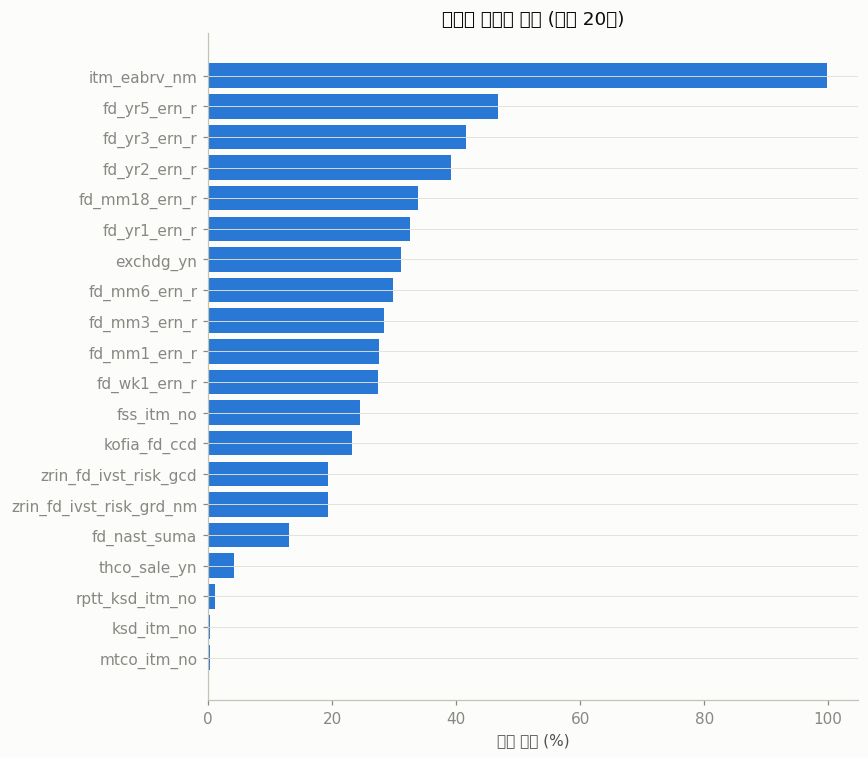

In [14]:
miss_top = missing[missing["missing_count"] > 0].head(20)
if len(miss_top):
    fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(miss_top))))
    ax.barh(miss_top.index[::-1], miss_top["missing_pct"][::-1], color=CAT_COLORS[0])
    ax.set_xlabel("결측 비율 (%)")
    ax.set_title("컬럼별 결측치 비율 (상위 20개)")
    plt.tight_layout()
    plt.show()
else:
    print("결측치가 있는 컬럼이 없습니다.")


## 6. 중복 및 기본키 무결성 체크

스키마상 `itm_no`, `prfd_attr_cd`, `zrin_fd_ivst_risk_gcd` 세 컬럼이 모두 `PK`로 표기되어 있어 각각 개별적으로 중복을 확인합니다.
`itm_no`(종목번호)가 유일하지 않다면 실제 PK가 다른 컬럼 조합(예: `itm_no` + 클래스 구분)일 가능성을 의심해야 합니다.

In [15]:
n_dup_rows = df.duplicated().sum()
print(f"완전 중복 행 수: {n_dup_rows:,}")

for pk_candidate in ["itm_no", "prfd_attr_cd", "zrin_fd_ivst_risk_gcd"]:
    if pk_candidate in df.columns:
        n_dup_pk = df[pk_candidate].duplicated().sum()
        print(f"{pk_candidate} 중복 건수: {n_dup_pk:,} / 전체 {len(df):,}건 "
              f"(고유값 {df[pk_candidate].nunique(dropna=False):,}개)")

if "itm_no" in df.columns and df["itm_no"].duplicated().any():
    display(df[df["itm_no"].duplicated(keep=False)].sort_values("itm_no").head(20))


완전 중복 행 수: 0
itm_no 중복 건수: 84,480 / 전체 95,619건 (고유값 11,139개)
prfd_attr_cd 중복 건수: 95,391 / 전체 95,619건 (고유값 228개)
zrin_fd_ivst_risk_gcd 중복 건수: 95,612 / 전체 95,619건 (고유값 7개)


,bmrk_eng_nm,bmrk_nm,curr_cd,exchdg_yn,fd_estb_ctry_cd,fd_ivst_rgn_desc,fd_mm18_ern_r,fd_mm1_ern_r,fd_mm3_ern_r,fd_mm6_ern_r,fd_nast_suma,fd_set_pcd,fd_wk1_ern_r,fd_yr1_ern_r,fd_yr2_ern_r,fd_yr3_ern_r,fd_yr5_ern_r,frc_bpr_itm_yn,fss_itm_no,hdge_fd_yn,int_dvd_desc,itm_abrv_nm,itm_eabrv_nm,itm_eng_nm,itm_nm,itm_no,kofia_fd_ccd,ksd_itm_no,mtco_itm_no,ofsfd_yn,or_attr_desc,or_co_xtn_itt_cd,ovrs_fd_desc,pers_corp_desc,pfiv_sale_cntl_tcd,prfd_attr_cd,prvo_fd_desc,prvo_pbff_desc,rptt_ksd_itm_no,sale_yn,std_itm_no,thco_sale_yn,trusc_xtn_itt_cd,zrin_fd_ivst_risk_gcd,zrin_fd_ivst_risk_grd_nm
63114,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF1,NaN,서울신종MMF1,서울신종MMF1,KR5010101401,NaN,KRZ500023820,31111,N,MMF,"40,011.0000",국내,해당없음,0.0000,C103,해당없음,공모,KR0000000000,판매완료,KR5205104064,NaN,"20,081.0000",NaN,NaN
57209,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF1,NaN,서울신종MMF1,서울신종MMF1,KR5010101401,NaN,KRZ500023820,31111,N,MMF,"40,011.0000",국내,해당없음,0.0000,D102,해당없음,공모,KR0000000000,판매완료,KR5205104064,NaN,"20,081.0000",NaN,NaN
3145,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF1,NaN,서울신종MMF1,서울신종MMF1,KR5010101401,NaN,KRZ500023820,31111,N,MMF,"40,011.0000",국내,해당없음,0.0000,V101,해당없음,공모,KR0000000000,판매완료,KR5205104064,NaN,"20,081.0000",NaN,NaN
88243,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF1,NaN,서울신종MMF1,서울신종MMF1,KR5010101401,NaN,KRZ500023820,31111,N,MMF,"40,011.0000",국내,해당없음,0.0000,C101,해당없음,공모,KR0000000000,판매완료,KR5205104064,NaN,"20,081.0000",NaN,NaN
68112,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF2,NaN,서울신종MMF2,서울신종MMF2,KR5010101402,NaN,KRZ500023830,31112,N,MMF,"40,011.0000",국내,법인,0.0000,V101,해당없음,공모,KR0000000000,판매완료,KR5205104072,NaN,"20,081.0000",NaN,NaN
41399,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF2,NaN,서울신종MMF2,서울신종MMF2,KR5010101402,NaN,KRZ500023830,31112,N,MMF,"40,011.0000",국내,법인,0.0000,C103,해당없음,공모,KR0000000000,판매완료,KR5205104072,NaN,"20,081.0000",NaN,NaN
20809,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF2,NaN,서울신종MMF2,서울신종MMF2,KR5010101402,NaN,KRZ500023830,31112,N,MMF,"40,011.0000",국내,법인,0.0000,D102,해당없음,공모,KR0000000000,판매완료,KR5205104072,NaN,"20,081.0000",NaN,NaN
70136,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF2,NaN,서울신종MMF2,서울신종MMF2,KR5010101402,NaN,KRZ500023830,31112,N,MMF,"40,011.0000",국내,법인,0.0000,C101,해당없음,공모,KR0000000000,판매완료,KR5205104072,NaN,"20,081.0000",NaN,NaN
57884,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF4,NaN,서울신종MMF 4,서울신종MMF 4,KR5010101404,NaN,KRZ500023850,31114,N,MMF,"40,011.0000",국내,해당없음,0.0000,V101,해당없음,공모,030410031114,판매완료,KR5205104155,NaN,"20,081.0000",NaN,NaN
54806,채권종합지수 1~2Y,채권종합지수 1~2년,KRW,NaN,0.0000,국내,NaN,NaN,NaN,NaN,NaN,10.0000,NaN,NaN,NaN,NaN,NaN,N,NaN,N,배당,서울신종MMF4,NaN,서울신종MMF 4,서울신종MMF 4,KR5010101404,NaN,KRZ500023850,31114,N,MMF,"40,011.0000",국내,해당없음,0.0000,C103,해당없음,공모,030410031114,판매완료,KR5205104155,NaN,"20,081.0000",NaN,NaN


## 7. Y/N 플래그 컬럼 분석

이 스키마에는 날짜형 컬럼이 없는 대신(국내채권마스터와의 차이점), `_yn`으로 끝나는 이진 플래그 컬럼이 여러 개 있습니다.
값 형태가 raw 데이터마다 `Y/N`, `1/0`, `True/False` 등으로 섞여 있을 수 있어 정규화 후 비율을 확인합니다.

In [16]:
def normalize_flag(s: pd.Series) -> pd.Series:
    '''Y/N, 1/0, True/False 등 혼재된 플래그 값을 문자열 Y/N으로 정규화.'''
    mapping = {
        "Y": "Y", "y": "Y", "1": "Y", 1: "Y", 1.0: "Y", True: "Y",
        "N": "N", "n": "N", "0": "N", 0: "N", 0.0: "N", False: "N",
    }
    return s.map(lambda v: mapping.get(v, v))


flag_summary_rows = []
for col in FLAG_COLS:
    normalized = normalize_flag(df[col])
    vc = normalized.fillna("(결측)").astype(str).value_counts()
    flag_summary_rows.append({
        "column": col,
        **{str(k): v for k, v in vc.items()},
    })

flag_summary = pd.DataFrame(flag_summary_rows).set_index("column")
flag_summary


,Y,(결측),N
column,,,
exchdg_yn,"44,987.0000",29762,"20,870.0000"
frc_bpr_itm_yn,572.0000,1,"95,046.0000"
hdge_fd_yn,NaN,66,"95,553.0000"
ofsfd_yn,NaN,1,"95,618.0000"
thco_sale_yn,"91,594.0000",4025,NaN


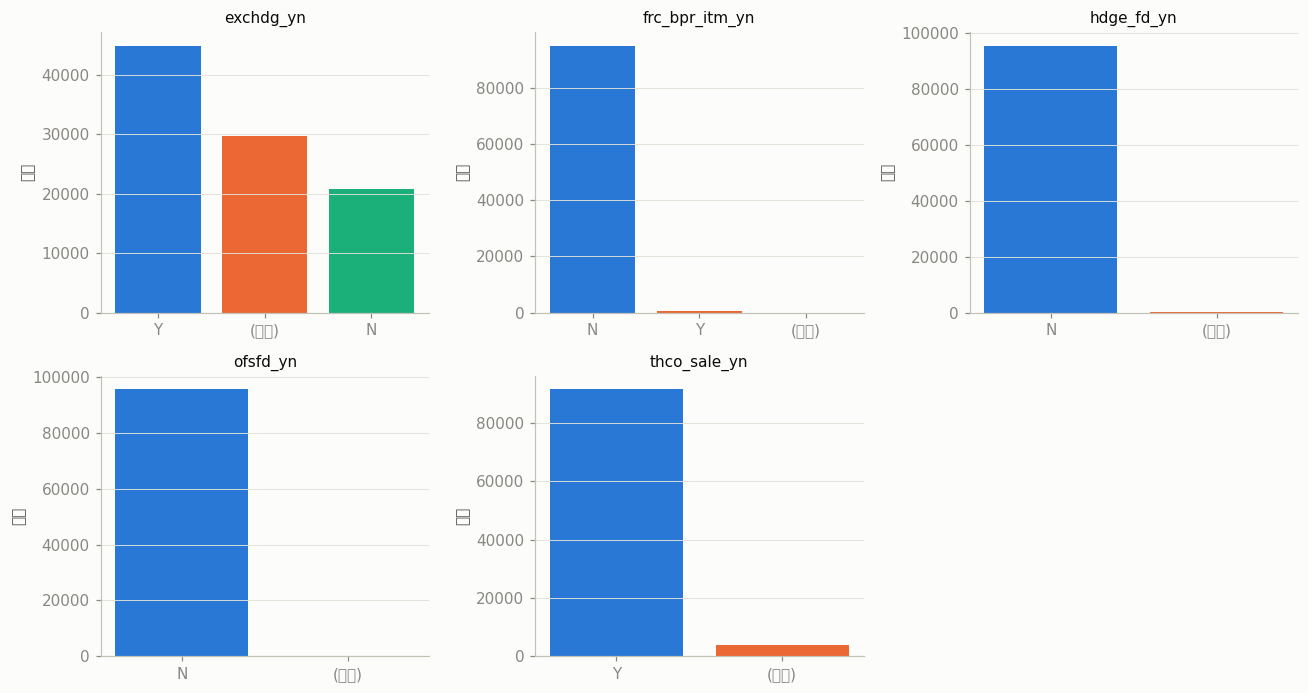

In [17]:
if FLAG_COLS:
    n_cols = 3
    n_rows = int(np.ceil(len(FLAG_COLS) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, FLAG_COLS):
        vc = normalize_flag(df[col]).fillna("(결측)").astype(str).value_counts()
        ax.bar([str(x) for x in vc.index], vc.values, color=cat_colors(len(vc)))
        ax.set_title(col, fontsize=10)
        ax.set_ylabel("건수")
    for ax in axes[len(FLAG_COLS):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 8. 파생 변수 생성

날짜형 컬럼이 없어 국내채권마스터의 "잔존만기 버킷"에 대응하는 파생 변수로 **순자산(AUM) 규모 구간**을 만듭니다.
절대 금액 임계값 대신 분위수 기반(`qcut`)으로 나눠 실제 데이터 스케일에 관계없이 동작하도록 했습니다.

In [18]:
if "fd_nast_suma" in df.columns and df["fd_nast_suma"].notna().sum() > 0:
    try:
        df["AUM_BUCKET"] = pd.qcut(
            df["fd_nast_suma"], q=5,
            labels=["Q1(최소)", "Q2", "Q3", "Q4", "Q5(최대)"],
            duplicates="drop",
        )
    except ValueError as e:
        print(f"qcut 분위 생성 실패(값 편중 가능성): {e}")

df[[c for c in ["fd_nast_suma", "AUM_BUCKET"] if c in df.columns]].head()


,fd_nast_suma,AUM_BUCKET
0,"77,291,400,582.0000",Q4
1,NaN,NaN
2,"71,147,860,091.0000",Q4
3,NaN,NaN
4,"600,482,482,202.0000",Q5(최대)


## 9. 범주형 변수 EDA

In [19]:
for col in CATEGORY_COLS:
    vc = df[col].value_counts(dropna=False)
    print(f"\n### {col} (고유값 {df[col].nunique(dropna=False)}개)")
    display(vc.head(10).to_frame("count").assign(pct=lambda x: (x["count"] / len(df) * 100).round(2)))



### fd_estb_ctry_cd (고유값 3개)


,count,pct
fd_estb_ctry_cd,,
0.0000,92838,97.0900
410.0000,2715,2.8400
NaN,66,0.0700



### fd_ivst_rgn_desc (고유값 8개)


,count,pct
fd_ivst_rgn_desc,,
글로벌,42875,44.8400
국내,33223,34.7500
아시아,10265,10.7400
남미/북미,4984,5.2100
이머징/브릭스,2261,2.3600
유럽,1846,1.9300
중동/아프리카,99,0.1000
NaN,66,0.0700



### fd_set_pcd (고유값 4개)


,count,pct
fd_set_pcd,,
10.0000,91354,95.5400
20.0000,3806,3.9800
0.0000,458,0.4800
NaN,1,0.0000


... (18 outputs left out)


### sale_yn (고유값 3개)


,count,pct
sale_yn,,
판매중,76318,79.8100
판매완료,19300,20.1800
NaN,1,0.0000



### pfiv_sale_cntl_tcd (고유값 4개)


,count,pct
pfiv_sale_cntl_tcd,,
0.0000,95014,99.3700
1.0000,430,0.4500
2.0000,109,0.1100
NaN,66,0.0700


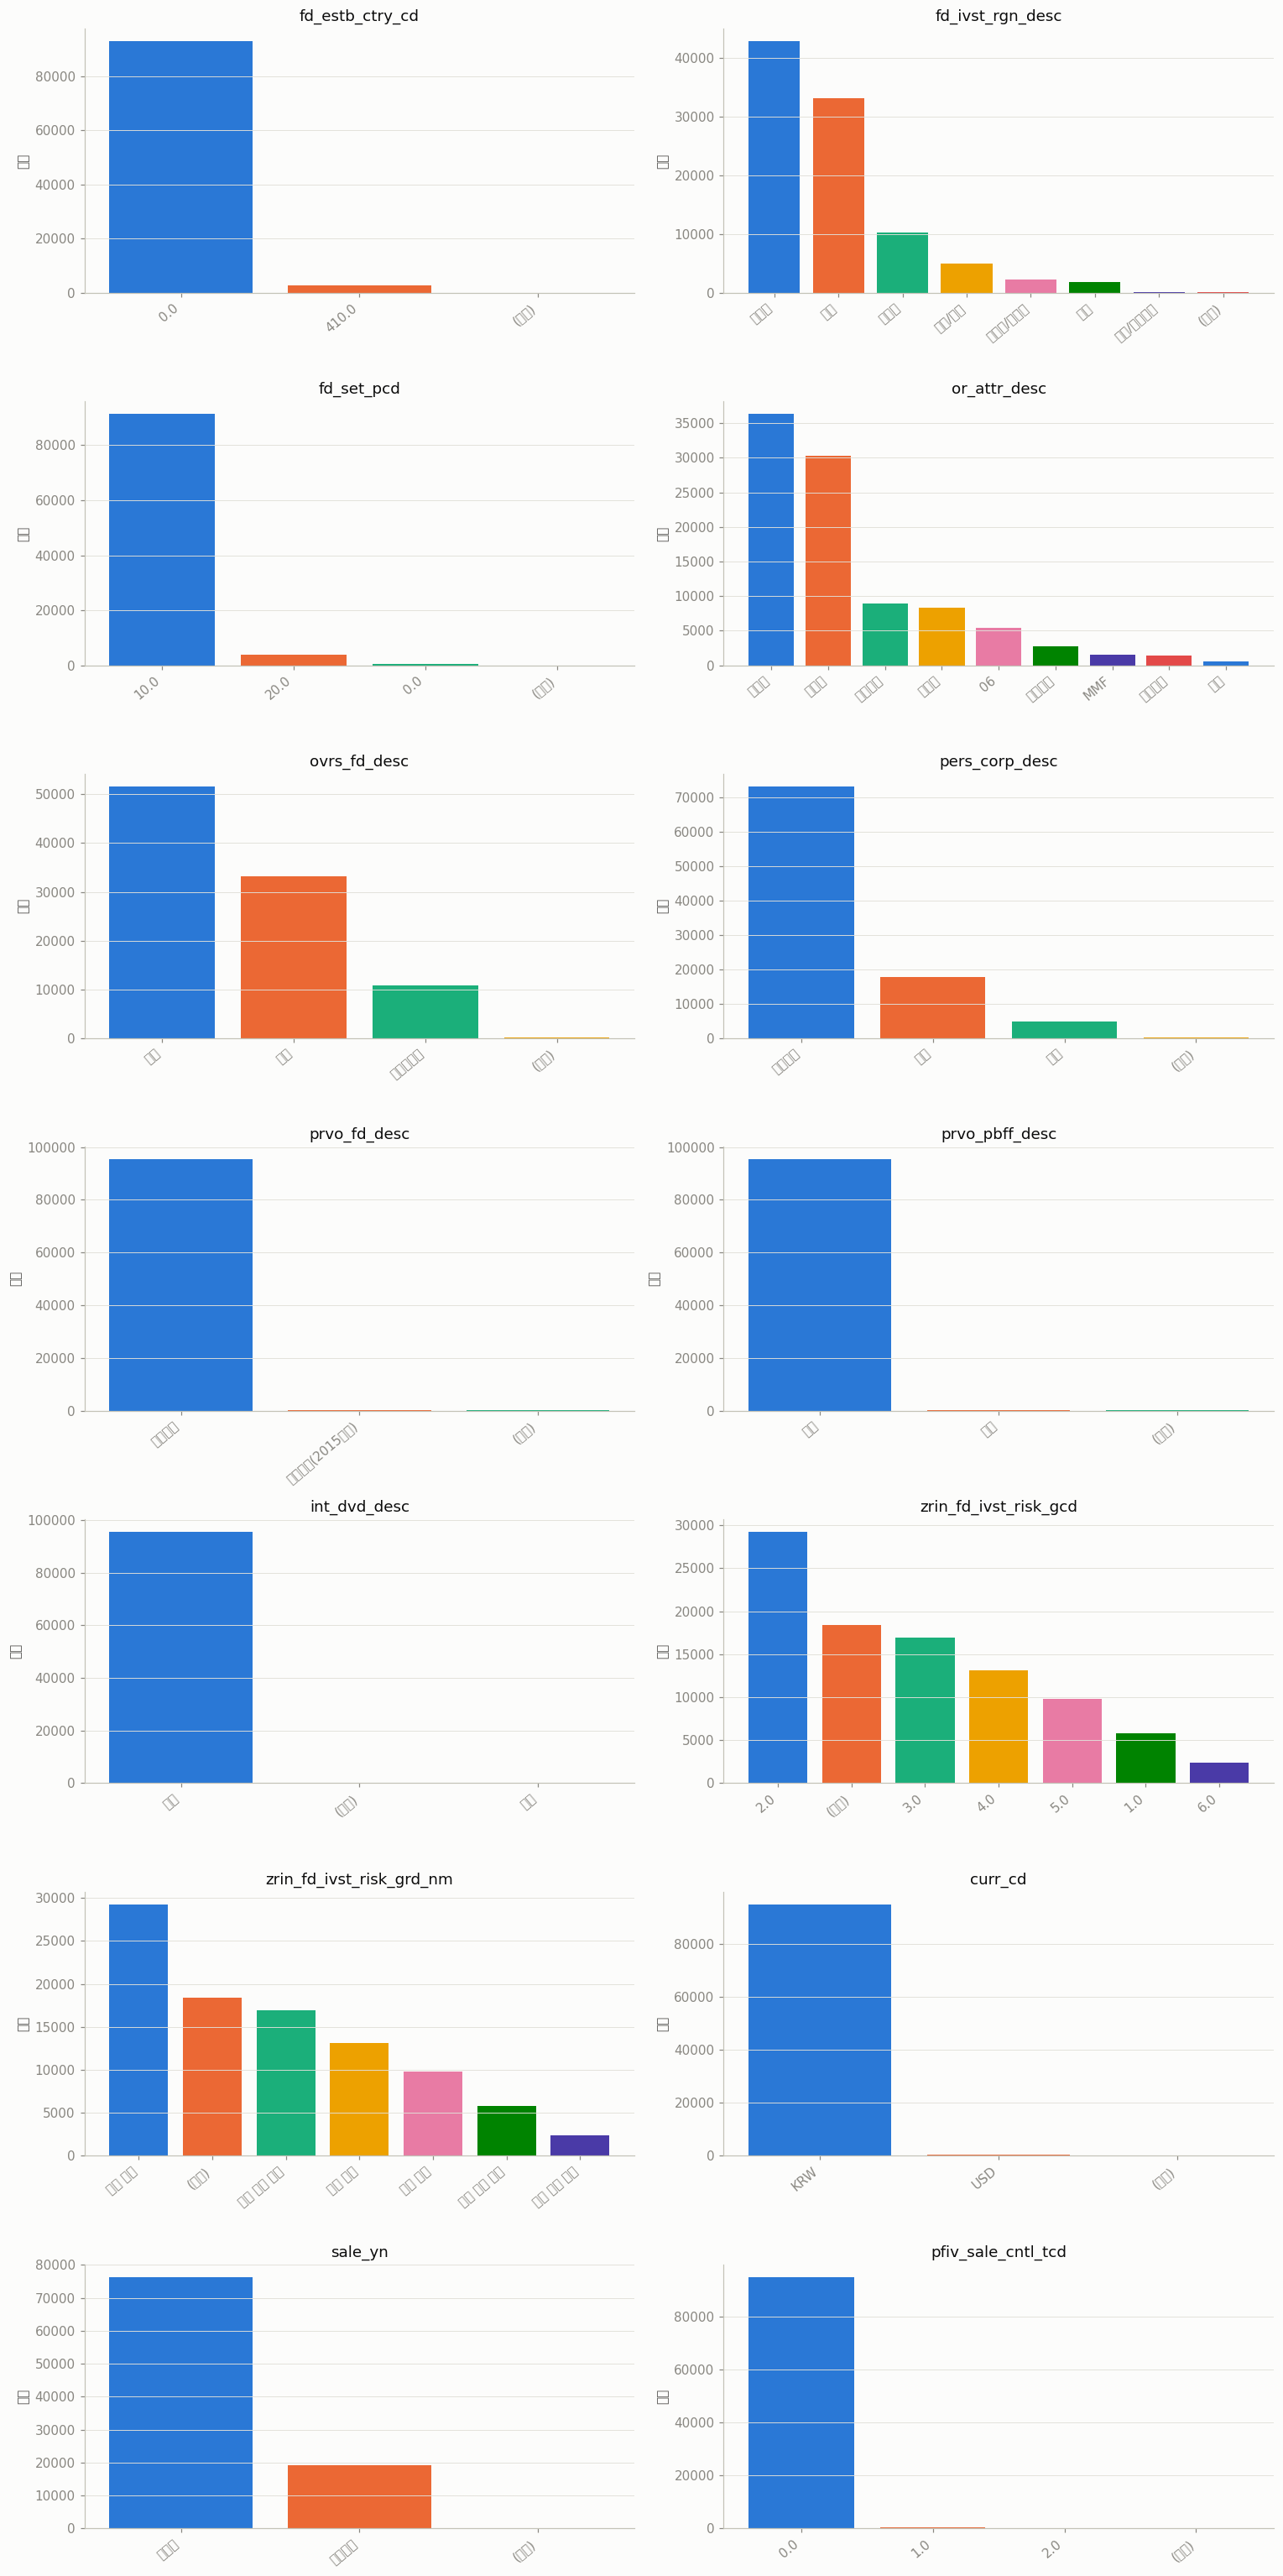

In [20]:
def plot_top_categories(col, top_n=8, ax=None):
    # NaN을 "(결측)" 문자열로 명시적으로 바꿔준 뒤 집계 (혼합 타입 인덱스로 인한 플로팅 오류 방지)
    vc = df[col].fillna("(결측)").astype(str).value_counts()
    top = vc.head(top_n)
    if len(vc) > top_n:
        other = pd.Series({"기타": vc.iloc[top_n:].sum()})
        top = pd.concat([top, other])

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(7, 4))
    colors = cat_colors(len(top))
    ax.bar([str(x) for x in top.index], top.values, color=colors)
    ax.set_title(col)
    ax.set_ylabel("건수")
    ax.tick_params(axis="x", rotation=40)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    if own_ax:
        plt.tight_layout()
        plt.show()


n_cols = 2
n_rows = int(np.ceil(len(CATEGORY_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, CATEGORY_COLS):
    plot_top_categories(col, ax=ax)
for ax in axes[len(CATEGORY_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. 수치형 변수 기술통계

In [21]:
stats = df[NUMERIC_COLS].describe().T
stats["skew"] = df[NUMERIC_COLS].skew()
stats["kurtosis"] = df[NUMERIC_COLS].kurtosis()
stats.sort_values("skew", ascending=False)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
fd_nast_suma,"83,081.0000","158,811,365,702.6445","566,067,818,518.4916",0.0000,"4,905,822,607.0000","28,247,840,372.0000","107,607,858,084.0000","28,359,162,282,520.0000",17.1948,572.0310
fd_yr1_ern_r,"64,426.0000",47.5706,73.2408,-92.5700,6.9025,23.3700,49.6900,975.1000,3.9303,31.1343
fd_mm6_ern_r,"67,169.0000",23.7872,38.8573,-84.1600,1.3300,10.0000,25.6700,369.6800,2.4384,9.3984
fd_mm3_ern_r,"68,543.0000",13.1384,19.2631,-88.4600,0.7600,7.6000,17.4900,144.2100,1.6530,4.3687
fd_wk1_ern_r,"69,452.0000",1.6214,4.3372,-60.9200,-0.5600,0.3400,2.1800,26.5900,1.0570,5.8035
fd_mm18_ern_r,"63,208.0000",58.7122,103.4059,"-3,593.0200",7.8325,24.9700,55.5800,"1,399.7700",0.3710,155.6503
fd_mm1_ern_r,"69,190.0000",-0.3417,4.0359,-63.1100,-0.9900,0.2200,1.2900,15.6500,-1.5935,9.8280
fd_yr2_ern_r,"58,129.0000",57.3612,84.3115,"-3,675.4400",12.4300,33.0600,62.9100,973.9500,-4.8610,346.7504
fd_yr3_ern_r,"55,813.0000",75.0449,100.6565,"-4,381.5600",19.6400,47.4400,89.7900,"1,142.5700",-5.2209,360.3477
fd_yr5_ern_r,"50,837.0000",55.6622,87.8404,"-4,254.7500",7.8300,34.2800,76.8300,611.5500,-10.4544,572.0410


## 11. 수치형 변수 분포 시각화

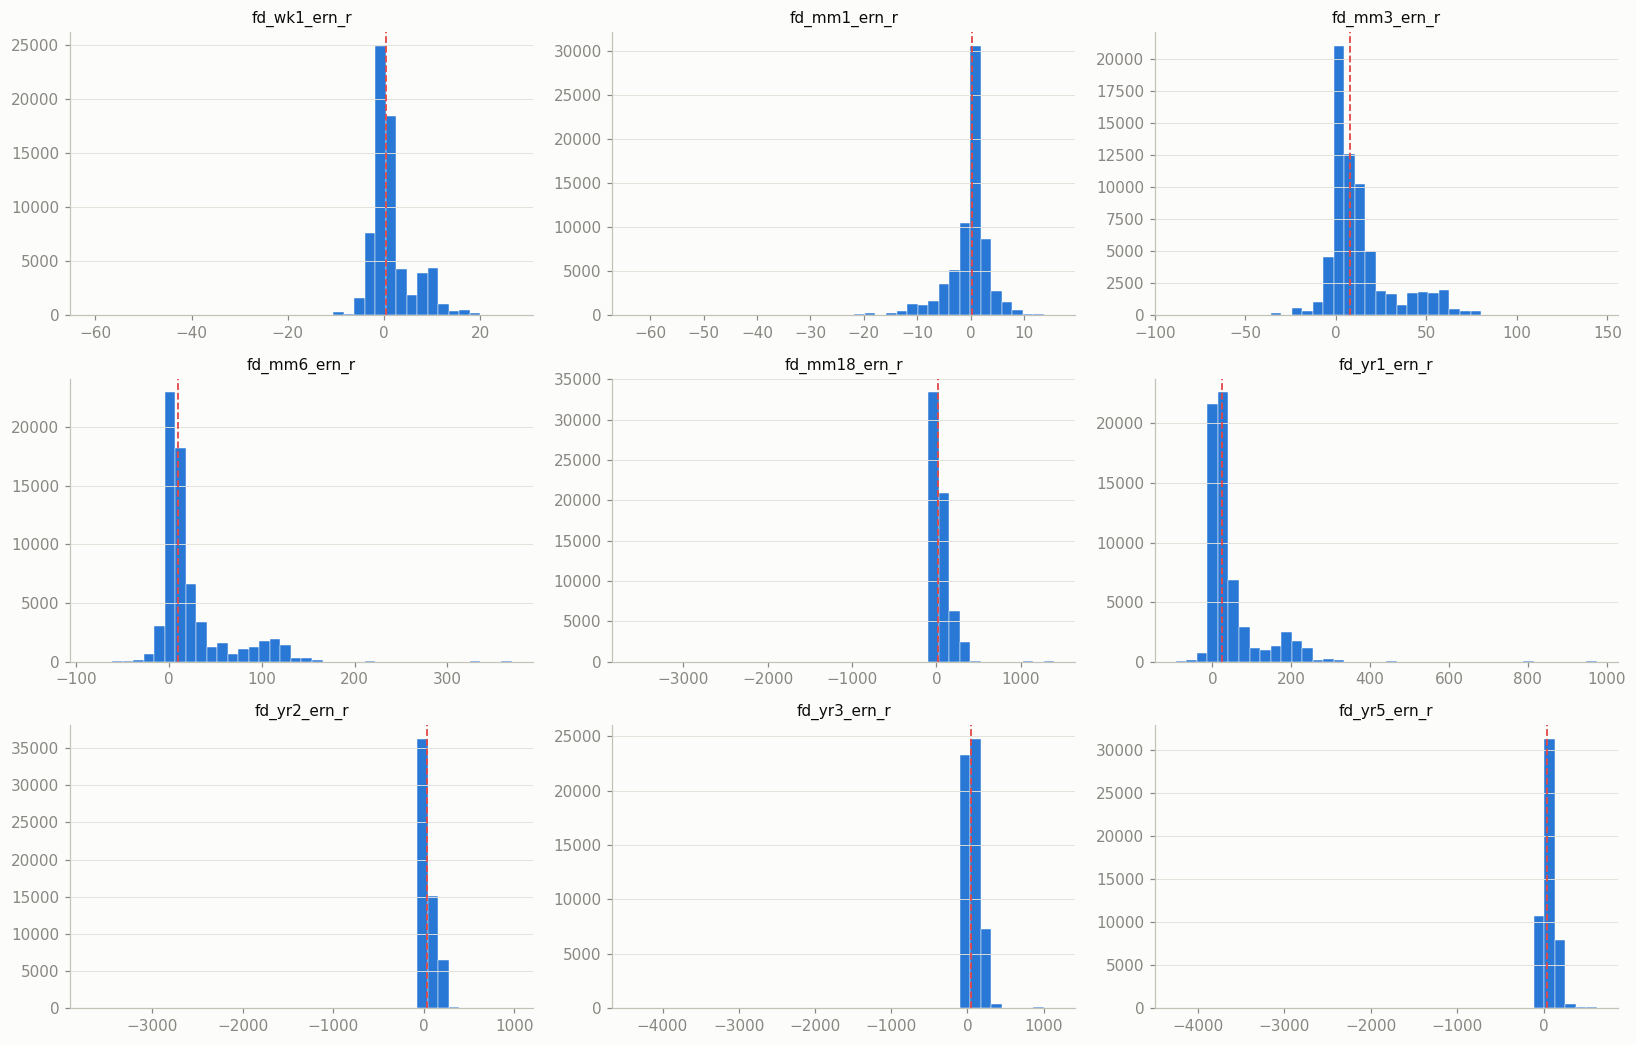

In [22]:
def plot_histograms(cols, n_cols=3, bins=40):
    n_rows = int(np.ceil(len(cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cols):
        data = df[col].dropna()
        ax.hist(data, bins=bins, color=CAT_COLORS[0], edgecolor="white", linewidth=0.3)
        ax.set_title(col, fontsize=10)
        ax.axvline(data.median(), color=CAT_COLORS[7], linewidth=1.2, linestyle="--", label="median")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_histograms(YIELD_COLS)


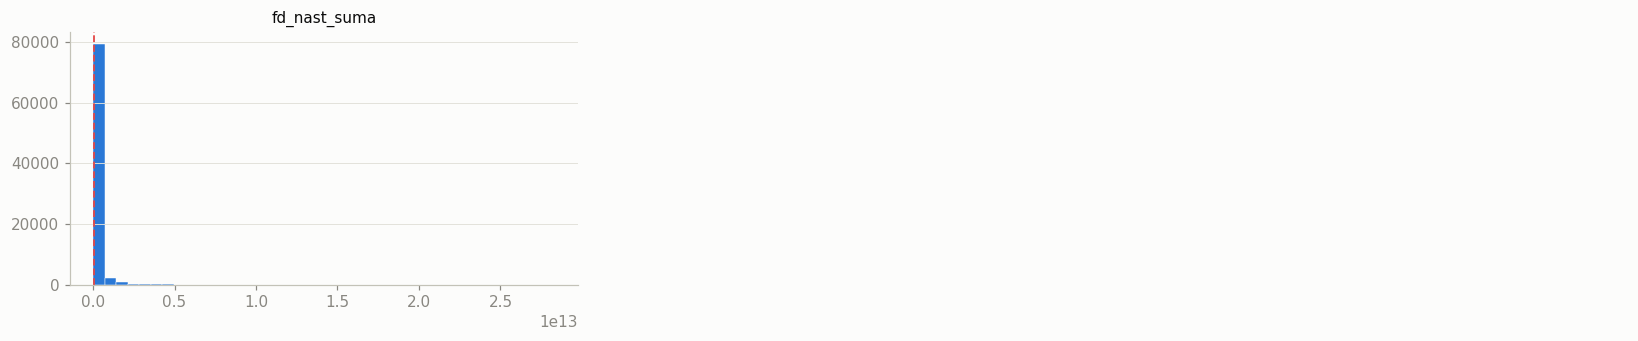

In [23]:
plot_histograms(AUM_COLS)


## 12. 이상치 탐지 (IQR 기준)

In [24]:
def iqr_outlier_summary(cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        rows.append({
            "column": col, "q1": q1, "q3": q3, "iqr": iqr,
            "lower": lo, "upper": hi,
            "n_outliers": n_out, "pct_outliers": round(n_out / len(s) * 100, 2),
        })
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False)


outlier_summary = iqr_outlier_summary(NUMERIC_COLS)
outlier_summary


,column,q1,q3,iqr,lower,upper,n_outliers,pct_outliers
0,fd_wk1_ern_r,-0.5600,2.1800,2.7400,-4.6700,6.2900,12019,17.3100
1,fd_mm1_ern_r,-0.9900,1.2900,2.2800,-4.4100,4.7100,11694,16.9000
4,fd_mm18_ern_r,7.8325,55.5800,47.7475,-63.7888,127.2013,9609,15.2000
3,fd_mm6_ern_r,1.3300,25.6700,24.3400,-35.1800,62.1800,9295,13.8400
5,fd_yr1_ern_r,6.9025,49.6900,42.7875,-57.2787,113.8712,8764,13.6000
6,fd_yr2_ern_r,12.4300,62.9100,50.4800,-63.2900,138.6300,7868,13.5400
9,fd_nast_suma,"4,905,822,607.0000","107,607,858,084.0000","102,702,035,477.0000","-149,147,230,608.5000","261,660,911,299.5000",10892,13.1100
7,fd_yr3_ern_r,19.6400,89.7900,70.1500,-85.5850,195.0150,6994,12.5300
2,fd_mm3_ern_r,0.7600,17.4900,16.7300,-24.3350,42.5850,8163,11.9100
8,fd_yr5_ern_r,7.8300,76.8300,69.0000,-95.6700,180.3300,5088,10.0100


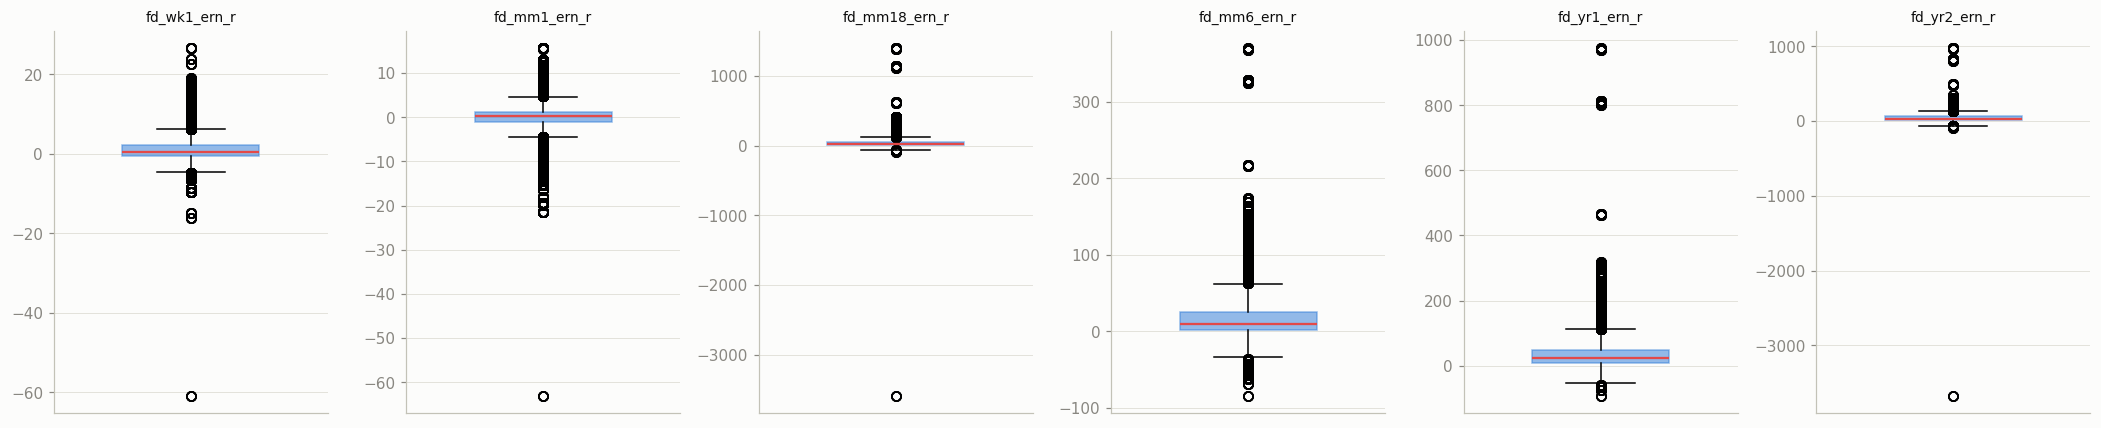

In [25]:
top_outlier_cols = outlier_summary.head(6)["column"].tolist()
if top_outlier_cols:
    fig, axes = plt.subplots(1, len(top_outlier_cols), figsize=(3.2 * len(top_outlier_cols), 4))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, top_outlier_cols):
        bp = ax.boxplot(df[col].dropna(), patch_artist=True, widths=0.5)
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COLORS[0], alpha=0.5, edgecolor=CAT_COLORS[0])
        for median in bp["medians"]:
            median.set(color=CAT_COLORS[7], linewidth=1.5)
        ax.set_title(col, fontsize=9)
        ax.set_xticks([])
    plt.tight_layout()
    plt.show()


## 13. 순자산(fd_nast_suma) 분석

,itm_no,itm_nm,or_attr_desc,prvo_pbff_desc,fd_nast_suma
244,KR5114601001,삼성KODEX200증권상장지수투자신탁[주식],주식형,공모,"28,359,162,282,520.0000"
5855,KR5114601001,삼성KODEX200증권상장지수투자신탁[주식],주식형,공모,"28,359,162,282,520.0000"
11363,KR5114601001,삼성KODEX200증권상장지수투자신탁[주식],주식형,공모,"28,359,162,282,520.0000"
16228,KR5114601001,삼성KODEX200증권상장지수투자신탁[주식],주식형,공모,"28,359,162,282,520.0000"
41009,KR5114601001,삼성KODEX200증권상장지수투자신탁[주식],주식형,공모,"28,359,162,282,520.0000"
61844,KR5114601001,삼성KODEX200증권상장지수투자신탁[주식],주식형,공모,"28,359,162,282,520.0000"
230,KR5014410031,삼성MMF법인제1호 Cp 클래스,MMF,공모,"12,440,162,407,400.0000"
2551,KR5014410039,삼성MMF법인 제1호_Cpe(퇴직연금),MMF,공모,"12,440,162,407,400.0000"
3976,KR5014410031,삼성MMF법인제1호 Cp 클래스,MMF,공모,"12,440,162,407,400.0000"
5536,KR5014410030,삼성MMF법인제1호 C 클래스,MMF,공모,"12,440,162,407,400.0000"


,count,sum,mean
or_attr_desc,,,
주식형,31831,"4,585,909,035,799,590.0000","144,070,529,854.5314"
재간접,27725,"3,266,231,406,759,346.0000","117,808,166,159.0386"
MMF,1049,"1,773,169,060,478,622.5000","1,690,342,288,349.4971"
채권형,7050,"1,268,075,874,751,862.5000","179,868,918,404.5195"
혼합자산,1414,"1,012,011,785,873,815.0000","715,708,476,572.7122"
06,3878,"610,470,470,555,412.8750","157,418,893,902.8914"
채권혼합,7541,"528,136,628,696,559.0000","70,035,357,206.8106"
주식혼합,2136,"140,019,459,842,461.0000","65,552,181,574.1859"
대출형,5,"5,391,179,456,605.0000","1,078,235,891,321.0000"


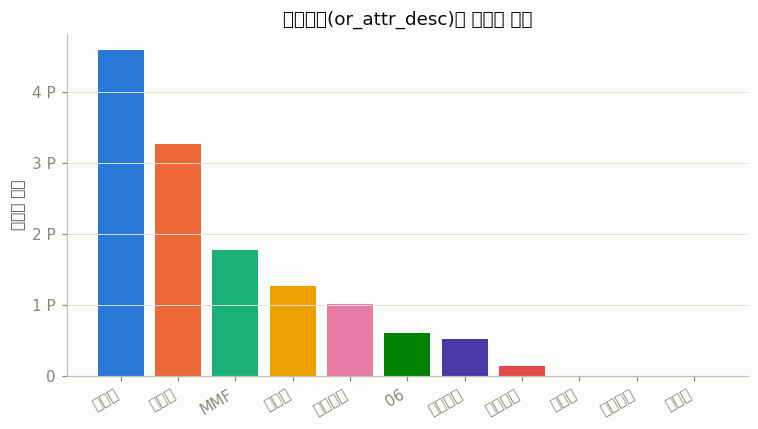

In [26]:
if "fd_nast_suma" in df.columns:
    top_funds = df.nlargest(20, "fd_nast_suma")[
        [c for c in ["itm_no", "itm_nm", "or_attr_desc", "prvo_pbff_desc", "fd_nast_suma"] if c in df.columns]
    ]
    display(top_funds)

    if "or_attr_desc" in df.columns:
        by_attr = (
            df.groupby("or_attr_desc")["fd_nast_suma"]
            .agg(["count", "sum", "mean"])
            .sort_values("sum", ascending=False)
        )
        display(by_attr)

        fig, ax = plt.subplots(figsize=(7, 4))
        colors = cat_colors(len(by_attr))
        ax.bar([str(x) for x in by_attr.index], by_attr["sum"], color=colors)
        ax.set_title("운용속성(or_attr_desc)별 순자산 합계")
        ax.set_ylabel("순자산 합계")
        ax.tick_params(axis="x", rotation=30)
        for label in ax.get_xticklabels():
            label.set_ha("right")
        ax.yaxis.set_major_formatter(mticker.EngFormatter())
        plt.tight_layout()
        plt.show()


## 14. 투자위험등급(zrin_fd_ivst_risk_gcd) 분석

,count
zrin_fd_ivst_risk_grd_nm,
높은 위험,29251
(결측),18417
다소 높은 위험,16892
보통 위험,13103
낮은 위험,9788
매우 높은 위험,5771
매우 낮은 위험,2397


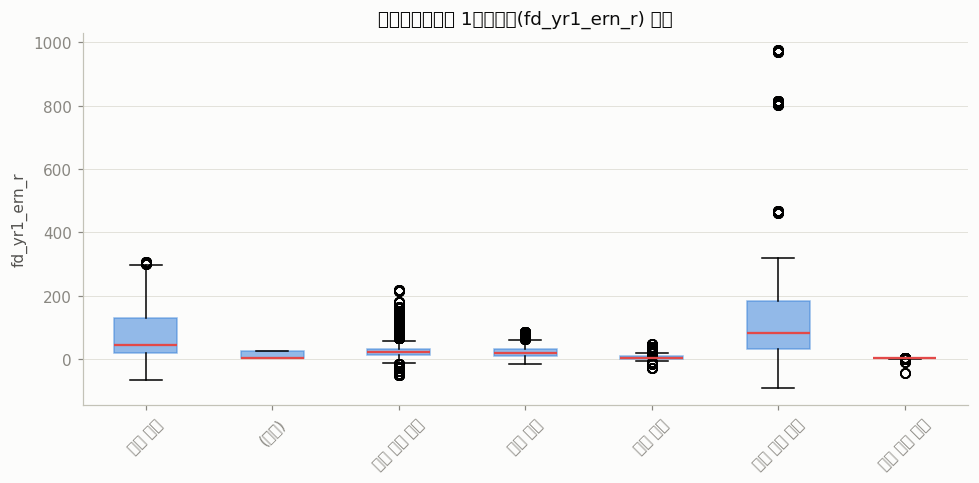

In [27]:
if "zrin_fd_ivst_risk_gcd" in df.columns:
    risk_col = "zrin_fd_ivst_risk_grd_nm" if "zrin_fd_ivst_risk_grd_nm" in df.columns else "zrin_fd_ivst_risk_gcd"
    risk_filled = df[risk_col].fillna("(결측)").astype(str)
    grade_counts = risk_filled.value_counts()
    display(grade_counts.to_frame("count"))

    if "fd_yr1_ern_r" in df.columns:
        order = grade_counts.index.tolist()
        fig, ax = plt.subplots(figsize=(9, 4.5))
        data_by_grade = [df.loc[risk_filled == g, "fd_yr1_ern_r"].dropna() for g in order]
        bp = ax.boxplot(data_by_grade, labels=[str(g) for g in order], patch_artist=True, widths=0.5)
        for box in bp["boxes"]:
            box.set(facecolor=CAT_COLORS[0], alpha=0.5, edgecolor=CAT_COLORS[0])
        for median in bp["medians"]:
            median.set(color=CAT_COLORS[7], linewidth=1.5)
        ax.set_title("투자위험등급별 1년수익률(fd_yr1_ern_r) 분포")
        ax.set_ylabel("fd_yr1_ern_r")
        ax.tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()


## 15. 수익률(Yield) 컬럼 간 비교

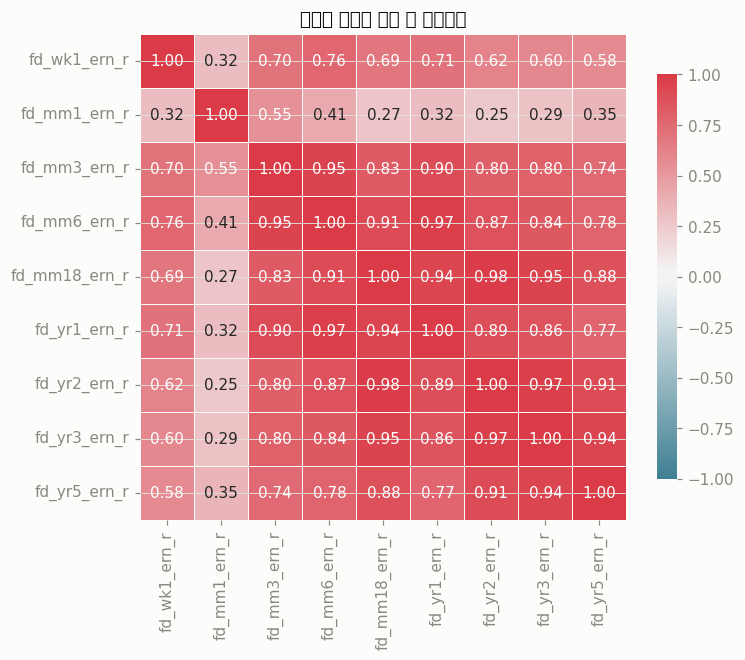

In [28]:
yield_corr = df[YIELD_COLS].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    yield_corr, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor=SURFACE,
    cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("기간별 수익률 컬럼 간 상관관계")
plt.tight_layout()
plt.show()


## 16. 순자산 vs 1년수익률 산점도

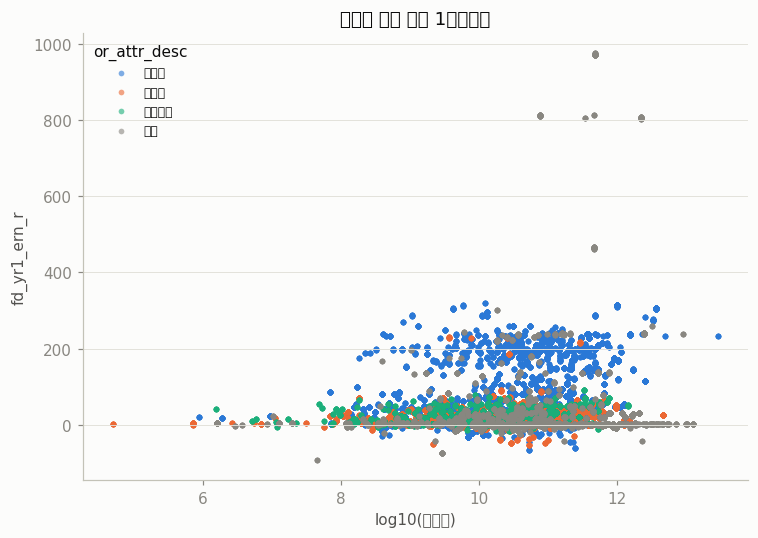

In [29]:
if {"fd_nast_suma", "fd_yr1_ern_r"}.issubset(df.columns):
    hue_col = "or_attr_desc" if "or_attr_desc" in df.columns else None

    fig, ax = plt.subplots(figsize=(7, 5))
    x = df["fd_nast_suma"]
    # 순자산은 규모 편차가 매우 커서 log 스케일로 표시
    x_log = np.log10(x.clip(lower=1))

    if hue_col:
        # 팔레트 규칙: scatter처럼 모든 쌍이 동시에 보이는 차트는 상위 3개 카테고리까지만
        # 검증된 색으로 표시하고 나머지는 '기타'로 묶습니다.
        top_cats = df[hue_col].value_counts().head(3).index.tolist()
        plot_df = df.copy()
        plot_df["_x_log"] = x_log
        plot_df[hue_col] = plot_df[hue_col].where(plot_df[hue_col].isin(top_cats), "기타")
        cats = top_cats + (["기타"] if plot_df[hue_col].eq("기타").any() else [])
        colors = CAT_COLORS[:len(top_cats)] + ([INK_MUTED] if "기타" in cats else [])
        for cat, color in zip(cats, colors):
            sub = plot_df[plot_df[hue_col] == cat]
            ax.scatter(sub["_x_log"], sub["fd_yr1_ern_r"], s=14, alpha=0.6, color=color, label=str(cat), linewidths=0)
        ax.legend(title=hue_col, frameon=False, fontsize=8)
    else:
        ax.scatter(x_log, df["fd_yr1_ern_r"], s=14, alpha=0.5, color=CAT_COLORS[0], linewidths=0)

    ax.set_xlabel("log10(순자산)")
    ax.set_ylabel("fd_yr1_ern_r")
    ax.set_title("순자산 규모 대비 1년수익률")
    plt.tight_layout()
    plt.show()


## 17. 수치형 변수 전체 상관관계

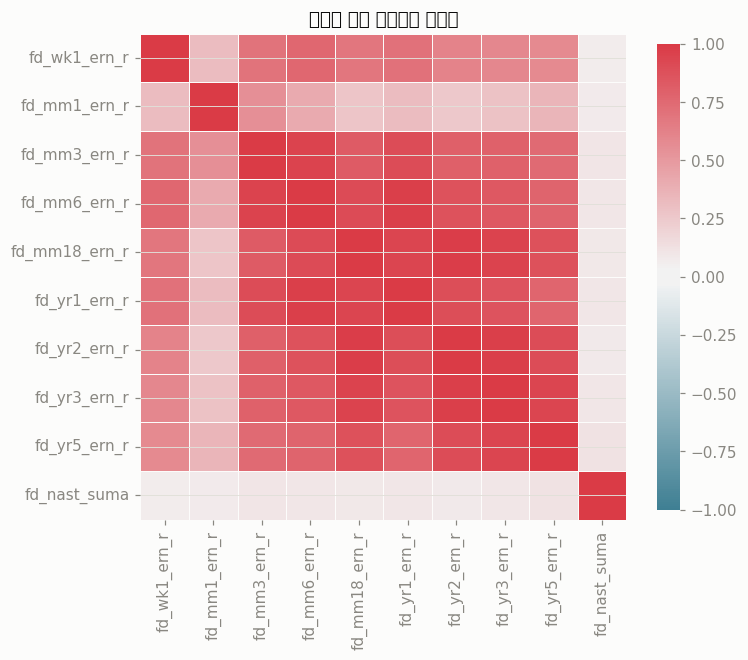

In [30]:
corr = df[NUMERIC_COLS].corr()
fig, ax = plt.subplots(figsize=(0.5 * len(NUMERIC_COLS) + 2, 0.5 * len(NUMERIC_COLS) + 2))
sns.heatmap(
    corr, cmap=DIVERGING_CMAP, center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.4, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax,
)
ax.set_title("수치형 변수 상관관계 히트맵")
plt.tight_layout()
plt.show()


In [31]:
# 상관관계 절대값 기준 상위 페어 (자기 자신 제외)
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename("corr")
    .to_frame()
    .assign(abs_corr=lambda x: x["corr"].abs())
    .sort_values("abs_corr", ascending=False)
)
corr_pairs.head(20)


,,corr,abs_corr
fd_mm18_ern_r,fd_yr2_ern_r,0.9805,0.9805
fd_mm6_ern_r,fd_yr1_ern_r,0.9723,0.9723
fd_yr2_ern_r,fd_yr3_ern_r,0.9722,0.9722
fd_mm18_ern_r,fd_yr3_ern_r,0.9508,0.9508
fd_mm3_ern_r,fd_mm6_ern_r,0.9482,0.9482
fd_yr3_ern_r,fd_yr5_ern_r,0.9420,0.9420
fd_mm18_ern_r,fd_yr1_ern_r,0.9392,0.9392
fd_mm6_ern_r,fd_mm18_ern_r,0.9101,0.9101
fd_yr2_ern_r,fd_yr5_ern_r,0.9062,0.9062
fd_mm3_ern_r,fd_yr1_ern_r,0.9015,0.9015


## 18. 운용속성(or_attr_desc)별 요약

In [32]:
if "or_attr_desc" in df.columns:
    agg_dict = {"itm_no": "count"}
    for c in ["fd_yr1_ern_r", "fd_yr3_ern_r", "fd_nast_suma"]:
        if c in df.columns:
            agg_dict[c] = "mean" if c != "fd_nast_suma" else "sum"

    summary_by_attr = df.groupby("or_attr_desc").agg(agg_dict).rename(columns={"itm_no": "종목수"})
    summary_by_attr.sort_values("종목수", ascending=False)


## 19. 공모/사모, 판매여부 교차분석

국내채권마스터에는 없는 이 데이터셋 고유의 특성(공모/사모 구분, 자사/전체 판매여부)을 교차표로 확인합니다.

In [33]:
if {"prvo_pbff_desc", "sale_yn"}.issubset(df.columns):
    display(pd.crosstab(df["prvo_pbff_desc"], df["sale_yn"], margins=True))

if {"prvo_pbff_desc", "thco_sale_yn"}.issubset(df.columns):
    display(pd.crosstab(df["prvo_pbff_desc"], normalize_flag(df["thco_sale_yn"]), margins=True))


sale_yn,판매완료,판매중,All
prvo_pbff_desc,,,
공모,19133,76318,95451
사모,102,0,102
All,19235,76318,95553


thco_sale_yn,Y,All
prvo_pbff_desc,,
공모,91489,91489
사모,40,40
All,91529,91529
